# Portfolio Optimisation with Reinforcement Learning

**Goal.** Learn a dynamic allocation strategy across a set of stocks and cash, rebalanced daily, that maximises risk-adjusted return, then test it honestly against simple and classical benchmarks.

| Component | Choice |
|---|---|
| Environment | Historical daily prices of 10 large US stocks plus cash, with transaction costs |
| State | Recent return, 20- and 60-day momentum, volatility and moving-average gap for each stock, plus current portfolio weights |
| Action | A weekly tilt for each stock of up to ±15 percentage points around equal weight. Weights can go negative (short), gross exposure is capped at 100%, and the remainder is held in cash. The portfolio moves halfway to the target at each rebalance. |
| Reward | Differential Sharpe ratio (Moody & Saffell, 2001): an online, per-step measure of each day's contribution to the Sharpe ratio |
| Agent | Proximal Policy Optimisation (PPO, Stable-Baselines3), trained with 5 random seeds |
| Comparison | Buy-and-hold, daily-rebalanced equal weight (1/N), minimum-variance, and an equal-weighted index of all S&P 500 stocks in the dataset |

The data are split chronologically into training (May 2013 – Jun 2016), validation (Jul – Dec 2016, used only to pick each seed's checkpoint) and an untouched test period (Jan 2017 – Feb 2018). Results are reported for every seed, not just the best one.

## 1. Setup and data

* **Data:** the Kaggle *S&P 500 stock data* dataset (Nugent, 2018; licence CC0: Public Domain), with daily prices for the 505 S&P 500 constituents from 8 February 2013 to 7 February 2018. It is loaded from the unchanged copy in Plotly's public `datasets` repository (MIT licence). Prices are split-adjusted but exclude dividends.
* **Market benchmark:** an equal-weighted index of all 505 stocks, built from the same dataset so that every input has a clear open licence.

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import gymnasium as gym
from gymnasium import spaces
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback

warnings.filterwarnings("ignore", category=UserWarning)
SEEDS = [0, 1, 2, 3, 4]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

STOCKS_URL = "https://raw.githubusercontent.com/plotly/datasets/master/all_stocks_5yr.csv"
raw = pd.read_csv(STOCKS_URL, parse_dates=["date"])
print(raw.shape, raw.Name.nunique(), "tickers,", raw.date.min().date(), "to", raw.date.max().date())

# Market benchmark: equal-weighted average daily return of all stocks in the dataset (one-day moves beyond
# ±40% are spin-offs or data errors and are excluded), compounded into an index.
all_close = raw.pivot(index="date", columns="Name", values="close").sort_index()
all_ret = all_close.pct_change()
all_ret = all_ret.mask(all_ret.abs() > 0.4)
market = (1 + all_ret.mean(axis=1).fillna(0)).cumprod()

(619040, 7) 505 tickers, 2013-02-08 to 2018-02-07


### 1.1 Universe selection without look-ahead

Picking stocks that went on to do well would bias the backtest. Instead, the universe is the **10 stocks with the highest average daily dollar volume over the first 60 trading days** of the data (February–May 2013). That rule uses only information available at the start, and it also guarantees liquid names, for which daily rebalancing is realistic.

In [2]:
dates = np.sort(raw.date.unique())
first60 = raw[raw.date < dates[60]]
dollar_vol = (first60.close * first60.volume).groupby(first60.Name).mean().sort_values(ascending=False)
UNIVERSE = list(dollar_vol.index[:10])
prices = raw[raw.Name.isin(UNIVERSE)].pivot(index="date", columns="Name", values="close")[UNIVERSE]
assert prices.notna().all().all(), "missing prices in universe"
market = market.reindex(prices.index)
print("Universe:", UNIVERSE)
(dollar_vol.head(10) / 1e9).round(2).rename("avg daily $ volume, Feb–May 2013 (bn)").to_frame().T

Universe: ['AAPL', 'GOOGL', 'BAC', 'MSFT', 'C', 'XOM', 'JPM', 'FB', 'INTC', 'T']


Name,AAPL,GOOGL,BAC,MSFT,C,XOM,JPM,FB,INTC,T
"avg daily $ volume, Feb–May 2013 (bn)",7.35,1.84,1.82,1.5,1.36,1.15,1.15,1.09,0.98,0.95


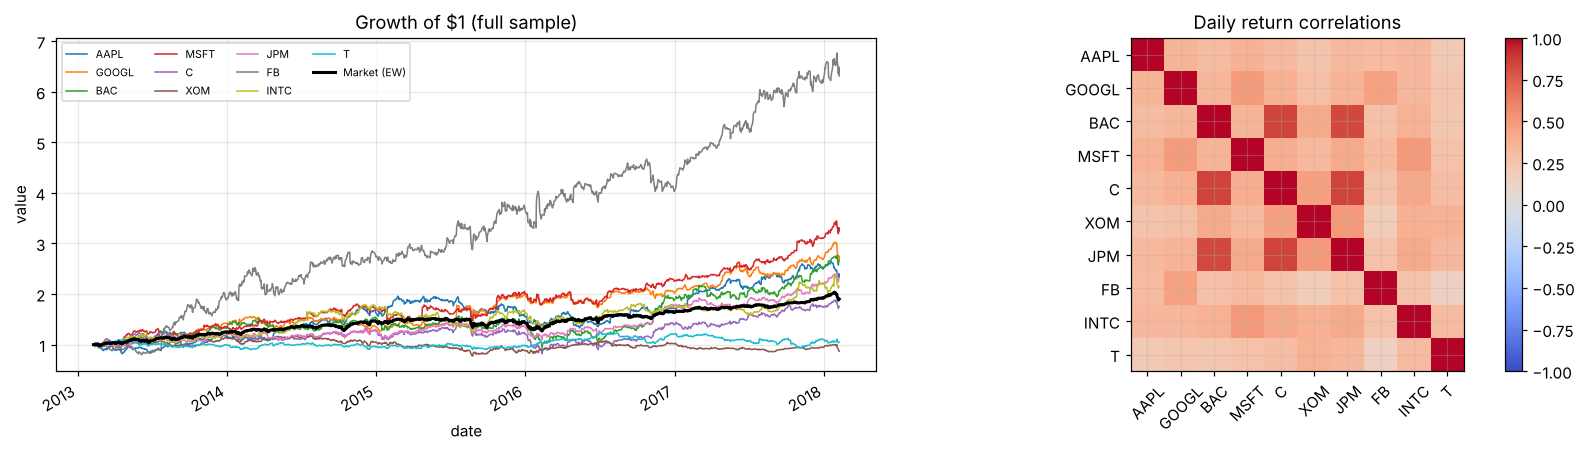

In [3]:
rets = prices.pct_change()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
(prices / prices.iloc[0]).plot(ax=axes[0], lw=1, legend=False)
(market / market.iloc[0]).plot(ax=axes[0], c="k", lw=2, label="Market (EW, all stocks)")
axes[0].set(title="Growth of $1 (full sample)", ylabel="value"); axes[0].legend(UNIVERSE + ["Market (EW)"], ncol=4, fontsize=7)
im = axes[1].imshow(rets.corr(), cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(10), UNIVERSE, rotation=45); axes[1].set_yticks(range(10), UNIVERSE)
axes[1].set_title("Daily return correlations"); plt.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

## 2. Features

For each stock and day *t*, features use only closing prices up to and including *t*. The action chosen at *t* earns the return from *t* to *t + 1*.

* last day's log return
* momentum (log return) over 20 and 60 days
* 20-day realised volatility
* distance from the 50-day moving average

A deliberately small feature set: with only about 160 weekly decisions in the training period, a large state invites overfitting. An earlier version with 16 features per stock, including 10 lagged returns and RSI, did worse on the validation period.

Features are standardised with training-period means and standard deviations.

In [4]:
logp = np.log(prices)
lr = logp.diff()
feats = {
    "ret_1d": lr,
    "mom_20": logp - logp.shift(20),
    "mom_60": logp - logp.shift(60),
    "vol_20": lr.rolling(20).std(),
    "ma50_gap": prices / prices.rolling(50).mean() - 1,
}
FEAT_NAMES = list(feats)
F = np.stack([feats[f].values for f in FEAT_NAMES], axis=-1)        # (T, N, n_feat)
next_ret = rets.shift(-1).values                                      # return earned by holding from t to t+1

valid = ~np.isnan(F).any(axis=(1, 2)) & ~np.isnan(next_ret).any(axis=1)
idx_dates = prices.index
PERIODS = {"train": ("2013-05-01", "2016-06-30"), "validation": ("2016-07-01", "2016-12-31"), "test": ("2017-01-01", "2018-02-07")}
mask = {k: valid & (idx_dates >= a) & (idx_dates <= b) for k, (a, b) in PERIODS.items()}
mu_f = F[mask["train"]].reshape(-1, F.shape[2]).mean(0)
sd_f = F[mask["train"]].reshape(-1, F.shape[2]).std(0)
Fz = np.clip((F - mu_f) / sd_f, -5, 5).astype(np.float32)
pd.DataFrame({k: {"start": idx_dates[m][0].date(), "end": idx_dates[m][-1].date(), "trading days": int(m.sum())} for k, m in mask.items()}).T

,start,end,trading days
train,2013-05-07,2016-06-30,795
validation,2016-07-01,2016-12-30,127
test,2017-01-03,2018-02-06,276


## 3. Trading environment

* **Rebalancing:** weekly (every 5 trading days). At each rebalance the agent outputs target weights; the portfolio moves **halfway** from its current weights to the target and then drifts with prices until the next rebalance. A first version of this notebook rebalanced fully every day: its agents turned over about 93% of the portfolio per day and lost heavily to transaction costs (see the README). Weekly, partial rebalancing is the standard remedy.
* **Action → weights:** the agent tilts around the equal-weight portfolio. Raw actions $a \in [-1, 1]^N$ give $\tilde w_i = 1/N + 0.15\,a_i$ (between −5% and +25% per stock, so short positions are possible), scaled by $\max(1, \sum_i |\tilde w_i|)$ so that gross exposure is at most 100%. The remainder $1 - \sum_i w_i$ sits in cash (zero return, a conservative assumption for 2013–2018 when short rates were near zero). Framing actions as tilts around a benchmark is standard in active portfolio management. An earlier version with unconstrained weights in [−1, 1] learned net-short positions in a rising market and lost on the validation period.
* **Start:** each episode begins from the equal-weight portfolio and pays the cost of buying it.
* **Costs:** 10 basis points per unit of turnover, charged at every rebalance.
* **Reward:** the differential Sharpe ratio $D_t$ of Moody & Saffell, computed on weekly portfolio returns net of costs. It tracks exponential moving averages $A_t$ and $B_t$ of the first and second moments of returns, and rewards each step by its marginal contribution to the Sharpe ratio:

$$D_t = \frac{B_{t-1}\,\Delta A_t - \tfrac12 A_{t-1}\,\Delta B_t}{(B_{t-1} - A_{t-1}^2)^{3/2}},\qquad \Delta A_t = R_t - A_{t-1},\; \Delta B_t = R_t^2 - B_{t-1}.$$

* **Episodes (training):** 52 weeks starting at a random week in the training period. **Evaluation:** one pass through the whole validation or test period, with daily returns recorded for the performance metrics.

In [5]:
COST = 0.001
HOLD = 5                          # rebalance every 5 trading days (weekly)
ADJUST = 0.5                      # move halfway from current to target weights at each rebalance
TILT = 0.15                       # maximum tilt per stock away from equal weight (15 percentage points)
ETA = 1 / 13                      # adaptation rate of the Sharpe moving averages (~ one quarter of weekly steps)


class PortfolioEnv(gym.Env):
    """Each step = one week. The agent sets target weights; the portfolio moves ADJUST of the way there,
    then drifts with prices for HOLD days. Daily returns are recorded for evaluation."""

    def __init__(self, period_mask, episode_weeks=52, random_start=True, seed=None):
        super().__init__()
        days = np.where(period_mask)[0]
        self.rebal_days = days[::HOLD]
        self.last_day = days[-1]
        self.N = Fz.shape[1]
        self.random_start = random_start
        self.episode_len = min(episode_weeks, len(self.rebal_days)) if random_start else len(self.rebal_days)
        obs_dim = self.N * Fz.shape[2] + self.N
        self.observation_space = spaces.Box(-np.inf, np.inf, (obs_dim,), np.float32)
        self.action_space = spaces.Box(-1.0, 1.0, (self.N,), np.float32)
        self.rng = np.random.default_rng(seed)

    def _obs(self):
        return np.concatenate([Fz[self.rebal_days[self.k]].ravel(), self.w.astype(np.float32)])

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.k0 = self.rng.integers(0, len(self.rebal_days) - self.episode_len + 1) if self.random_start else 0
        self.k = self.k0
        self.w = np.full(self.N, 1.0 / self.N)           # start from the equal-weight portfolio...
        self.entry_cost = COST * 1.0                     # ...and pay the cost of buying it on the first step
        self.A, self.B = 0.0, 1e-3
        self.value, self.history = 1.0, []
        return self._obs(), {}

    @staticmethod
    def to_weights(a):
        """Tilt around equal weight: w_i = 1/N + TILT * a_i, then scaled so gross exposure <= 1; the rest is cash."""
        a = np.clip(np.asarray(a, dtype=float), -1, 1)
        w = 1.0 / len(a) + TILT * a
        return w / max(1.0, np.abs(w).sum())

    def step(self, action):
        t = self.rebal_days[self.k]
        target = self.to_weights(action)
        w_new = self.w + ADJUST * (target - self.w)
        cost = COST * np.abs(w_new - self.w).sum() + self.entry_cost
        self.entry_cost = 0.0
        w, week_growth = w_new.copy(), 1.0 - cost
        end = min(t + HOLD, self.last_day + 1)
        for j, d in enumerate(range(t, end)):
            r_day = float(w @ next_ret[d]) - (cost if j == 0 else 0.0)
            self.value *= 1 + r_day
            week_growth *= 1 + float(w @ next_ret[d])
            self.history.append({"date": idx_dates[d + 1], "return": r_day, "value": self.value, "cost": cost if j == 0 else 0.0,
                                 **{f"w_{s}": wi for s, wi in zip(UNIVERSE, w)}})
            w = w * (1 + next_ret[d]) / (1 + w @ next_ret[d])
        self.w = w
        R = week_growth - 1
        dA, dB = R - self.A, R**2 - self.B
        denom = max(self.B - self.A**2, 1e-8) ** 1.5
        reward = (self.B * dA - 0.5 * self.A * dB) / denom
        self.A += ETA * dA; self.B += ETA * dB
        self.k += 1
        done = self.k >= self.k0 + self.episode_len
        obs = np.zeros(self.observation_space.shape, np.float32) if done else self._obs()
        return obs, float(np.clip(reward, -10, 10)) * 0.1, done, False, {}


def run_policy(policy_fn, period):
    env = PortfolioEnv(mask[period], random_start=False)
    obs, _ = env.reset()
    done = False
    while not done:
        obs, _, done, _, _ = env.step(policy_fn(obs, env))
    return pd.DataFrame(env.history).set_index("date")

## 4. Performance metrics

In [6]:
def perf(daily_returns, turnover=None):
    r = pd.Series(daily_returns).dropna()
    value = (1 + r).cumprod()
    ann_ret = value.iloc[-1] ** (252 / len(r)) - 1
    ann_vol = r.std() * np.sqrt(252)
    out = {"total return": value.iloc[-1] - 1, "annual return": ann_ret, "annual volatility": ann_vol,
           "Sharpe": r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else np.nan,
           "max drawdown": (value / value.cummax() - 1).min()}
    if turnover is not None:
        out["avg daily turnover"] = turnover
    return out

## 5. Benchmarks

* **Buy-and-hold:** equal weights at the start of the period, never rebalanced.
* **Equal weight (1/N), daily rebalanced:** a notoriously hard benchmark to beat (DeMiguel, Garlappi & Uppal, 2009).
* **Minimum-variance (long-only):** weights minimise the sample covariance over the previous 252 days, re-estimated every 21 trading days.
* **Market index:** the equal-weighted average return of all stocks in the dataset (no transaction costs charged).

The stock strategies pay the same 10 bp transaction cost on turnover.

In [7]:
N = len(UNIVERSE)

def buy_and_hold(period):
    w0 = np.full(N, 1 / N)
    vals, out = w0.copy(), []
    for j, t in enumerate(np.where(mask[period])[0]):
        if j == 0:
            R = vals @ next_ret[t] - COST * np.abs(w0).sum()
        else:
            R = vals @ next_ret[t]
        vals = vals * (1 + next_ret[t]) / (1 + vals @ next_ret[t])
        out.append((idx_dates[t + 1], R))
    return pd.Series(dict(out))

def min_var_weights(window):
    S = np.cov(window.T)
    cons = ({"type": "eq", "fun": lambda w: w.sum() - 1},)
    res = minimize(lambda w: w @ S @ w, np.full(N, 1 / N), bounds=[(0, 1)] * N, constraints=cons, method="SLSQP")
    return res.x

def min_variance(period, lookback=252, rebalance=21):
    w_prev, w_tgt, out = np.zeros(N), None, []
    for j, t in enumerate(np.where(mask[period])[0]):
        if j % rebalance == 0:
            w_tgt = min_var_weights(rets.values[t - lookback + 1:t + 1])
            cost = COST * np.abs(w_tgt - w_prev).sum(); w_hold = w_tgt
        else:
            cost = 0.0; w_hold = w_prev
        R = w_hold @ next_ret[t] - cost
        w_prev = w_hold * (1 + next_ret[t]) / (1 + w_hold @ next_ret[t])
        out.append((idx_dates[t + 1], R))
    return pd.Series(dict(out))

def equal_weight_daily(period):
    w_tgt, w_prev, out = np.full(N, 1 / N), np.zeros(N), []
    for t in np.where(mask[period])[0]:
        cost = COST * np.abs(w_tgt - w_prev).sum()
        R = w_tgt @ next_ret[t] - cost
        w_prev = w_tgt * (1 + next_ret[t]) / (1 + w_tgt @ next_ret[t])
        out.append((idx_dates[t + 1], R))
    return pd.Series(dict(out))

def market_returns(period):
    t = np.where(mask[period])[0]
    return pd.Series(market.pct_change().shift(-1).values[t], index=idx_dates[t + 1])

benchmarks = {}
for period in ("validation", "test"):
    benchmarks[period] = {
        "Buy-and-hold (equal start)": buy_and_hold(period),
        "Equal weight 1/N (daily)": equal_weight_daily(period),
        "Minimum variance (monthly)": min_variance(period),
        "Market, equal-weighted (all stocks)": market_returns(period),
    }
pd.DataFrame({k: perf(v) for k, v in benchmarks["test"].items()}).T.round(3)

,total return,annual return,annual volatility,Sharpe,max drawdown
Buy-and-hold (equal start),0.250,0.226,0.116,1.815,-0.076
Equal weight 1/N (daily),0.240,0.217,0.114,1.775,-0.076
Minimum variance (monthly),0.248,0.224,0.114,1.828,-0.076
"Market, equal-weighted (all stocks)",0.156,0.141,0.085,1.603,-0.076


## 6. Training the PPO agent

Each seed trains for 100,000 weekly steps (about 1,900 random one-year episodes). Every 5,000 steps the deterministic policy is evaluated on the **validation** period, and the checkpoint with the highest validation Sharpe ratio is kept. The test period is not touched until all five agents are final.

In [8]:
class ValidationCheckpoint(BaseCallback):
    def __init__(self, every=5_000):
        super().__init__()
        self.every, self.best, self.best_state, self.log = every, -np.inf, None, []

    def _on_step(self):
        if self.num_timesteps % self.every == 0:
            pol = lambda obs, env: self.model.predict(obs, deterministic=True)[0]
            val = run_policy(pol, "validation")
            s = perf(val["return"])["Sharpe"]
            self.log.append((self.num_timesteps, s))
            if s > self.best:
                self.best = s
                self.best_state = {k: v.clone() for k, v in self.model.policy.state_dict().items()}
        return True


TIMESTEPS = 100_000
agents, val_logs = {}, {}
t0 = time.time()
for seed in SEEDS:
    torch.manual_seed(seed)
    env = PortfolioEnv(mask["train"], seed=seed)
    model = PPO("MlpPolicy", env, learning_rate=3e-4, n_steps=2048, batch_size=256, n_epochs=10,
                gamma=0.9, gae_lambda=0.95, ent_coef=0.0, clip_range=0.2,
                policy_kwargs=dict(net_arch=[128, 128]), seed=seed, verbose=0, device="cpu")
    cb = ValidationCheckpoint()
    model.learn(total_timesteps=TIMESTEPS, callback=cb)
    model.policy.load_state_dict(cb.best_state)
    agents[seed], val_logs[seed] = model, pd.DataFrame(cb.log, columns=["timesteps", "validation Sharpe"])
    print(f"seed {seed}: best validation Sharpe {cb.best:.2f} at {val_logs[seed].loc[val_logs[seed]['validation Sharpe'].idxmax(), 'timesteps']:,} steps"
          f"  ({time.time() - t0:.0f}s elapsed)")

seed 0: best validation Sharpe 3.61 at 30,000 steps  (54s elapsed)


seed 1: best validation Sharpe 3.51 at 5,000 steps  (101s elapsed)


seed 2: best validation Sharpe 3.74 at 15,000 steps  (150s elapsed)


seed 3: best validation Sharpe 3.86 at 15,000 steps  (199s elapsed)


seed 4: best validation Sharpe 3.90 at 15,000 steps  (251s elapsed)


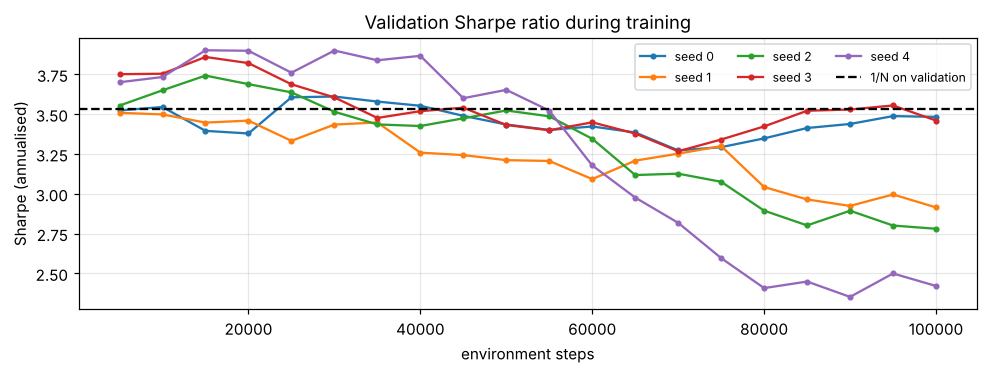

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for seed, log in val_logs.items():
    ax.plot(log.timesteps, log["validation Sharpe"], marker="o", ms=3, label=f"seed {seed}")
ax.axhline(perf(benchmarks["validation"]["Equal weight 1/N (daily)"])["Sharpe"], c="k", ls="--", label="1/N on validation")
ax.set(title="Validation Sharpe ratio during training", xlabel="environment steps", ylabel="Sharpe (annualised)")
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

## 7. Out-of-sample test (January 2017 – February 2018)

In [10]:
rl_runs = {}
for seed, model in agents.items():
    rl_runs[seed] = run_policy(lambda obs, env, m=model: m.predict(obs, deterministic=True)[0], "test")

def turnover(df):
    w = df[[c for c in df.columns if c.startswith("w_")]].values
    return np.abs(np.diff(w, axis=0)).sum(1).mean()

rows = {f"PPO seed {s}": perf(df["return"], turnover(df)) for s, df in rl_runs.items()}
rows.update({k: perf(v) for k, v in benchmarks["test"].items()})
table = pd.DataFrame(rows).T
rl_part = table.loc[[f"PPO seed {s}" for s in SEEDS]]
summary_row = rl_part.mean().rename("PPO mean of 5 seeds")
table = pd.concat([table, summary_row.to_frame().T])
fmt = {c: "{:.1%}" for c in ["total return", "annual return", "annual volatility", "max drawdown", "avg daily turnover"]}
fmt["Sharpe"] = "{:.2f}"
table.style.format(fmt, na_rep="–")

,total return,annual return,annual volatility,Sharpe,max drawdown,avg daily turnover
PPO seed 0,19.8%,18.0%,11.1%,1.54,-7.2%,3.2%
PPO seed 1,24.1%,21.8%,11.3%,1.80,-7.5%,1.1%
PPO seed 2,23.4%,21.1%,11.1%,1.78,-7.1%,2.1%
PPO seed 3,24.2%,21.9%,11.5%,1.78,-7.4%,1.9%
PPO seed 4,22.9%,20.8%,11.2%,1.75,-7.2%,1.9%
Buy-and-hold (equal start),25.0%,22.6%,11.6%,1.81,-7.6%,–
Equal weight 1/N (daily),24.0%,21.7%,11.4%,1.78,-7.6%,–
Minimum variance (monthly),24.8%,22.4%,11.4%,1.83,-7.6%,–
"Market, equal-weighted (all stocks)",15.6%,14.1%,8.5%,1.60,-7.6%,–
PPO mean of 5 seeds,22.9%,20.7%,11.2%,1.73,-7.3%,2.0%


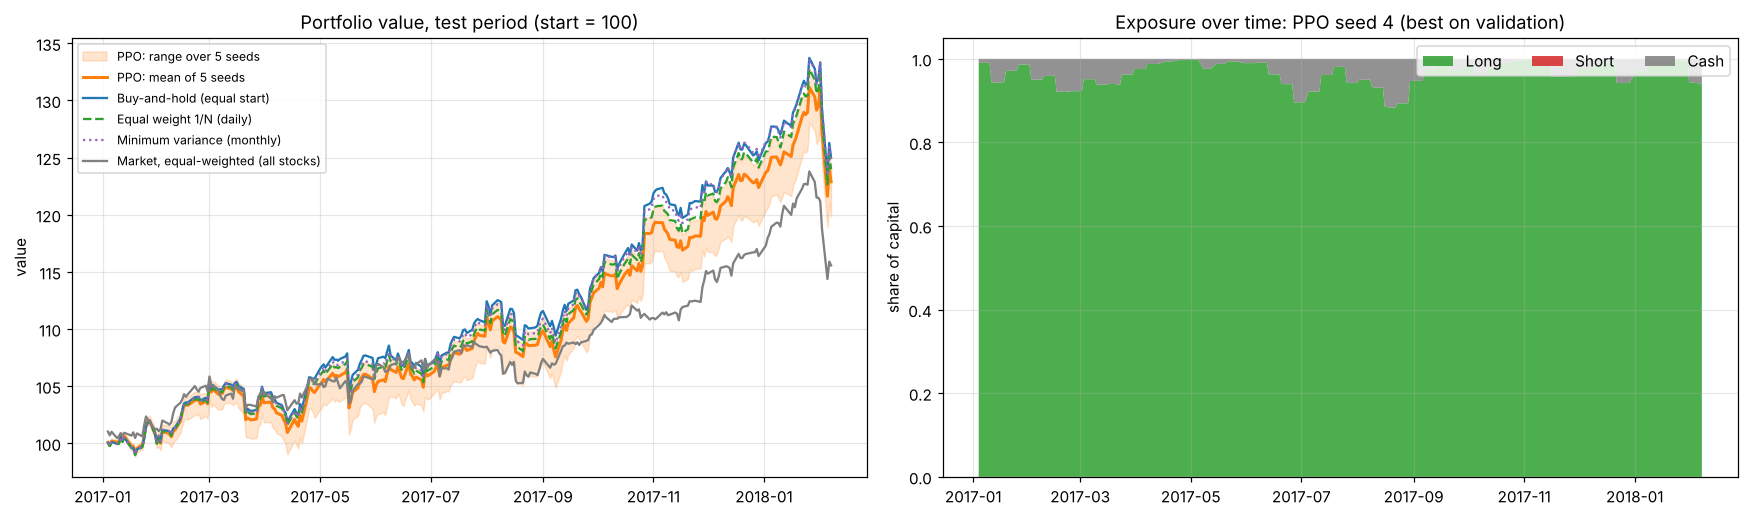

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ax = axes[0]
vals = pd.DataFrame({s: (1 + df["return"]).cumprod() * 100 for s, df in rl_runs.items()})
ax.fill_between(vals.index, vals.min(axis=1), vals.max(axis=1), color="tab:orange", alpha=0.2, label="PPO: range over 5 seeds")
ax.plot(vals.index, vals.mean(axis=1), c="tab:orange", lw=2, label="PPO: mean of 5 seeds")
style = {"Buy-and-hold (equal start)": ("tab:blue", "-"), "Equal weight 1/N (daily)": ("tab:green", "--"),
         "Minimum variance (monthly)": ("tab:purple", ":"), "Market, equal-weighted (all stocks)": ("gray", "-")}
for name, r in benchmarks["test"].items():
    c, ls = style[name]
    ax.plot((1 + r).cumprod() * 100, c=c, ls=ls, label=name)
ax.set(title="Portfolio value, test period (start = 100)", ylabel="value"); ax.legend(fontsize=8)

ax = axes[1]
best_val_seed = max(SEEDS, key=lambda s: val_logs[s]["validation Sharpe"].max())
w = rl_runs[best_val_seed][[f"w_{s}" for s in UNIVERSE]]
long_, short_ = w.clip(lower=0).sum(axis=1), -w.clip(upper=0).sum(axis=1)
cash = 1 - long_ - short_
ax.stackplot(w.index, long_, short_, cash, colors=["tab:green", "tab:red", "tab:gray"], labels=["Long", "Short", "Cash"], alpha=0.85)
ax.set(title=f"Exposure over time: PPO seed {best_val_seed} (best on validation)", ylabel="share of capital", ylim=(0, 1.05))
ax.legend(loc="upper right", ncol=3); plt.tight_layout(); plt.show()

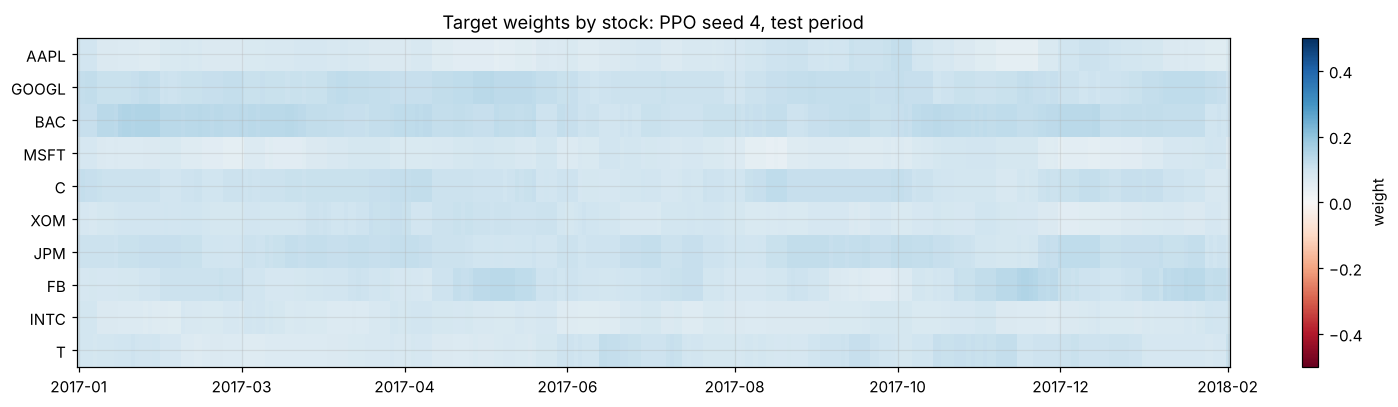

In [12]:
fig, ax = plt.subplots(figsize=(14, 3.8))
im = ax.imshow(w.T.values, aspect="auto", cmap="RdBu", vmin=-0.5, vmax=0.5)
ax.set_yticks(range(N), UNIVERSE)
tick = np.linspace(0, len(w) - 1, 8).astype(int)
ax.set_xticks(tick, [w.index[i].strftime("%Y-%m") for i in tick])
ax.set_title(f"Target weights by stock: PPO seed {best_val_seed}, test period"); plt.colorbar(im, ax=ax, label="weight")
plt.tight_layout(); plt.show()

## 8. Results and discussion

In [13]:
bench_sharpes = {k: perf(v)["Sharpe"] for k, v in benchmarks["test"].items()}
rl_sharpes = rl_part["Sharpe"]
print(f"PPO test Sharpe across seeds: mean {rl_sharpes.mean():.2f}, sd {rl_sharpes.std():.2f}, "
      f"min {rl_sharpes.min():.2f}, max {rl_sharpes.max():.2f}")
print("Seeds beating 1/N on Sharpe:", int((rl_sharpes > bench_sharpes['Equal weight 1/N (daily)']).sum()), "of", len(SEEDS))
print("Seeds beating the market index on Sharpe:", int((rl_sharpes > bench_sharpes['Market, equal-weighted (all stocks)']).sum()), "of", len(SEEDS))
print("Seeds beating the market index on total return:", int((rl_part['total return'] > perf(benchmarks['test']['Market, equal-weighted (all stocks)'])['total return']).sum()), "of", len(SEEDS))

PPO test Sharpe across seeds: mean 1.73, sd 0.11, min 1.54, max 1.80
Seeds beating 1/N on Sharpe: 3 of 5
Seeds beating the market index on Sharpe: 4 of 5
Seeds beating the market index on total return: 5 of 5


**How to read the results**

* The test table reports **every seed**. RL results in finance are notoriously sensitive to the random seed, and reporting only the best run would overstate what the method achieves. The spread across seeds is itself a finding.
* The **1/N** portfolio and the **market index** are the benchmarks that matter. The test period (2017 to early 2018) was an unusually calm, strongly rising market, ending with the volatility spike of early February 2018. Strategies that hold cash or go short tend to lag in such a period, even when they are better risk-managed.
* The exposure chart shows *how* the agent behaves: how much it holds long, short and in cash, and whether that changes with market conditions. The weight heat map shows which stocks it favours.

**Limitations.**
* The sample is short: about 3 years of training data and one test year with a single market regime. A robust evaluation would use walk-forward retraining over many years and regimes.
* Prices exclude dividends for all strategies and benchmarks alike, so total returns are slightly understated.
* Shorting costs, borrow availability and market impact are ignored beyond the flat 10 bp cost.
* The universe is fixed at the start date, so it avoids look-ahead bias but is not representative of the whole market.
* PPO hyperparameters were set once and not tuned. Tuning on the validation period would add selection bias unless done carefully.

In [14]:
print({"numpy": np.__version__, "pandas": pd.__version__, "torch": torch.__version__,
       "stable-baselines3": __import__("stable_baselines3").__version__, "gymnasium": gym.__version__})

{'numpy': '2.5.3', 'pandas': '3.0.5', 'torch': '2.15.0+cu132', 'stable-baselines3': '2.9.2', 'gymnasium': '1.4.0'}
